# Cap. 7 · Monte Carlo (GBM) y anomalías
*Proyecto DAT 262 · Monitor de estrés cambiario y monetario de Bolivia*

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from stress_monitor import data, stationarity as stat, markov as mk, forecasting as fc, gap as gp, simulation as sim, demo
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
m = data.load_monthly(); d = data.load_daily_key()
print("Datos mensuales:", m.index.min().date(), "→", m.index.max().date(), f"({len(m)} meses)")

Datos mensuales: 1989-01-31 → 2026-10-31 (454 meses)


**GBM:** $S_t=S_0\exp\{(\mu-\sigma^2/2)t+\sigma W_t\}$. Los parámetros se estiman con los log-retornos recientes.

{'mu': 0.02428893450156518, 'sigma': 0.09076203296346398, 'n': 36}
P(terminal < umbral) = 13.7% | P(cruce) = 26.8%


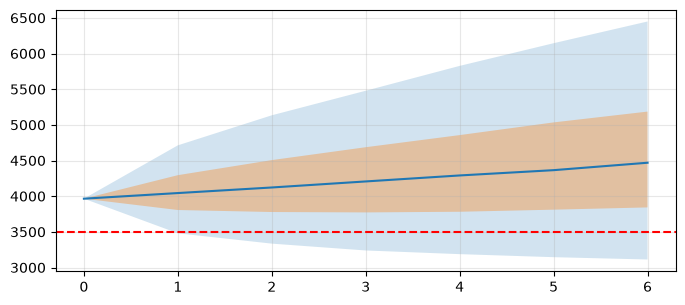

In [2]:
rs = sim.reserves_simulation(m['rib'], horizon=6, threshold=3500.0)
print(rs['params']); print('P(terminal < umbral) = %.1f%% | P(cruce) = %.1f%%' % (100*rs['p_terminal'], 100*rs['p_cruce']))
f = rs['fan']; fig, ax = plt.subplots(figsize=(8, 3.4)); ax.fill_between(f.index, f.p5, f.p95, alpha=.2); ax.fill_between(f.index, f.p25, f.p75, alpha=.35); ax.plot(f.p50); ax.axhline(3500, c='r', ls='--')

### Costo en bolivianos de una deuda en dólares
σ estimada con el TCO diario del BCB desde ago-2026 (excluye el salto jun→jul). El rango depende del régimen y de los supuestos.

{'ok': True, 'n': 104, 'mu_diario': -0.0004, 'sigma_diario': 0.0173, 'sigma_anual': np.float64(0.3303), 's0': 11.67, 'fecha': Timestamp('2026-11-13 00:00:00')}


{'hoy': 116700, 'p5': 87784, 'p50': 114972, 'p95': 150921, 'media': 116549, 'var95_extra': 34221}


Text(0.5, 1.0, 'Costo en Bs de USD 10.000 a 90 días')

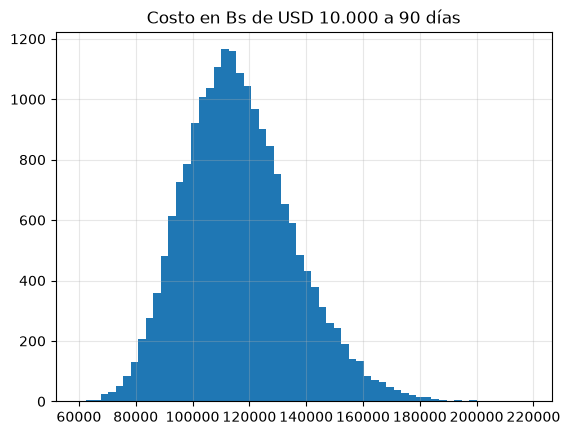

In [3]:
p = sim.fx_params(data.official_points(m, d)); print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in p.items()})
c = sim.fx_cost_simulation(10_000, 90, p['s0'], 0.0, p['sigma_diario'])
print({k: round(v) for k, v in c.items() if k != 'sims'})
plt.hist(c['sims'], 60); plt.title('Costo en Bs de USD 10.000 a 90 días')

### Detección de anomalías: residuos de SARIMA con |z| > 2,5

            residuo_z  anomalia
date                           
2010-12-31      -5.19      True
2021-03-31       2.66      True
2023-05-31      -8.69      True
2023-06-30       2.51      True
2026-05-31       3.57      True


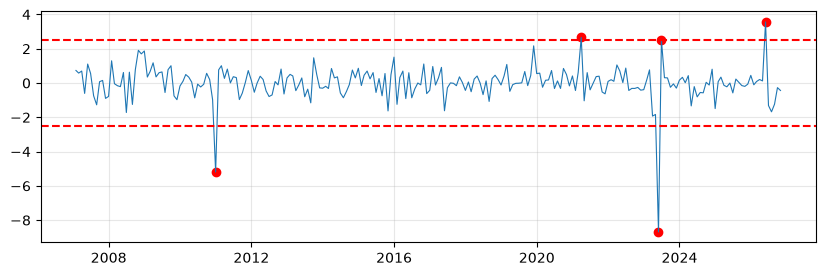

In [4]:
a = fc.full_analysis(m, 'depositos_me', steps=6)['anom']
print(a[a.anomalia].tail(8).round(2))
fig, ax = plt.subplots(figsize=(10, 3)); ax.plot(a.residuo_z, lw=.8); ax.axhline(2.5, c='r', ls='--'); ax.axhline(-2.5, c='r', ls='--'); ax.scatter(a.index[a.anomalia], a.residuo_z[a.anomalia], c='r')